# visits_v1: слои, аналитика, сжатый и несжатый вид

```
visits_v1.tsv ──load.py──▶ s3://raw ──transform.py──▶ s3://warehouse
 (текст, 2.5 ГБ)            Parquet+zstd, все колонки      Parquet+zstd, типы, схлопнуто,
                            binary, как в TSV              партиции по дню, сортировка
```

1. Слои: что меняется на каждом переходе.
2. Один визит через все слои.
3. Аналитика (по `warehouse`).
4. Те же запросы по несжатому TSV и по `warehouse`.

In [1]:
import json, statistics, time, urllib.request
import boto3, matplotlib.pyplot as plt, pandas as pd
from pyspark.sql import SparkSession, functions as F

from raw import read_raw, RAW_NAMES
from transform import typed_visits, collapse

spark = SparkSession.builder.appName("analytics").getOrCreate()
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 60)
plt.rcParams["figure.figsize"] = (10, 3.5)
s3 = boto3.client("s3", endpoint_url="http://garage:3900", region_name="garage")

raw = read_raw(spark, "s3a://raw/visits/batch=2014-03/")
visits = spark.read.parquet("s3a://warehouse/visits")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/17 09:39:09 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


26/10/17 09:39:10 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-s3a-file-system.properties,hadoop-metrics2.properties


## 1. Слои

| Переход | Что происходит |
|---|---|
| TSV → raw (`load.py`) | текст режется на части по 131 072 строки и пишется в Parquet + zstd. Значения не меняются: все 181 колонка `binary`, снято только TSV-экранирование. Добавлены `_part`, `_row` — откуда строка. |
| raw → warehouse (`transform.py`) | типы (числа, даты, `NULL`), массивы `[..]` → `array`, вложенные группы (`Goals.*` и др.) → `array<struct>`, схлопывание по `Sign`, партиции по дню, сортировка по счётчику. |

In [2]:
def prefix_size(bucket, prefix):
    n = b = 0
    for page in s3.get_paginator("list_objects_v2").paginate(Bucket=bucket, Prefix=prefix):
        for o in page.get("Contents", []):
            if o["Key"].endswith(".parquet"):
                n += 1; b += o["Size"]
    return n, b

m = json.loads(s3.get_object(Bucket="raw", Key="visits/batch=2014-03/manifest.json")["Body"].read())
layers = [
    ("TSV", "текст, без сжатия", m["rows"], 1, m["tsv_bytes"]),
    ("raw", "Parquet+zstd, binary как в TSV", raw.count(), *prefix_size("raw", "visits/")),
    ("warehouse", "Parquet+zstd, типы, схлопнуто", visits.count(), *prefix_size("warehouse", "visits/")),
]
sizes = pd.DataFrame(layers, columns=["слой", "формат", "строк", "файлов", "байт"])
sizes["МБ"] = (sizes["байт"] / 2**20).round(1)
sizes["от TSV"] = (sizes["байт"] / m["tsv_bytes"]).map("{:.1%}".format)
sizes = sizes.drop(columns="байт")
sizes

,слой,формат,строк,файлов,МБ,от TSV
0,TSV,"текст, без сжатия",1686859,1,2534.3,100.0%
1,raw,"Parquet+zstd, binary как в TSV",1686859,13,452.6,17.9%
2,warehouse,"Parquet+zstd, типы, схлопнуто",1676581,7,447.7,17.7%


## 2. Один визит через все слои

Берём визит, у которого в исходных данных была отмена (`Sign = -1`) и есть цели.

In [3]:
KEY = ["counter_id", "start_date", "user_id", "visit_id"]
k = (raw.select(*[F.col(c).cast("string").alias(c) for c in KEY + ["sign"]])
     .groupBy(*KEY).agg(F.count("*").alias("n"), F.min("sign").alias("min_sign"))
     .where("n = 3 AND min_sign = '-1'"))
v = (visits.select(*[F.col(c).cast("string").alias(c) for c in KEY], F.size("goals").alias("g"))
     .where("g > 1").join(k, KEY).orderBy("counter_id", "visit_id").first())
key = {c: v[c] for c in KEY}
where_raw = " AND ".join(f"CAST({c} AS STRING) = '{key[c]}'" for c in KEY)
where = " AND ".join(f"{c} = '{key[c]}'" for c in KEY)
print(key)

{'counter_id': '10040391', 'start_date': '2014-03-20', 'user_id': '1333133943427528256', 'visit_id': '7677919079884699762'}


**TSV** — исходные строки файла (первые 12 из 181 поля):

In [4]:
pos = raw.where(where_raw).select("_part", "_row").collect()
lines = {int(r["_part"].split("part-")[1][:5]) * m["rows_per_part"] + r["_row"] for r in pos}
with open("/data/visits_v1.tsv", "rb") as f:
    for i, line in enumerate(f):
        if i in lines:
            print(f"строка {i}:", " | ".join(x.decode(errors="replace") for x in line.split(b"\t")[:12]))
        if i > max(lines):
            break

строка 285867: 10040391 | 2014-03-20 | -1 | 0 | 7677919079884699762 | 1333133943427528256 | 2014-03-20 13:40:56 | 17 | 2014-03-20 15:40:21 | 4 | 6 | 0
строка 285868: 10040391 | 2014-03-20 | 1 | 0 | 7677919079884699762 | 1333133943427528256 | 2014-03-20 13:40:56 | 1507 | 2014-03-20 15:40:21 | 29 | 16 | 0


строка 1075542: 10040391 | 2014-03-20 | 1 | 0 | 7677919079884699762 | 1333133943427528256 | 2014-03-20 03:56:22 | 17 | 2014-03-20 12:12:06 | 4 | 6 | 0


**raw** — те же три строки: те же байты, плюс `_part`/`_row`:

In [5]:
(raw.where(where_raw)
 .select(*[F.col(c).cast("string").alias(c) for c in ["counter_id", "start_date", "sign", "visit_id",
                                                     "duration", "page_views", "goals__id"]], "_part", "_row")
 .orderBy("_part", "_row").toPandas())

,counter_id,start_date,sign,visit_id,duration,page_views,goals__id,_part,_row
0,10040391,2014-03-20,-1,7677919079884699762,17,4,"[1174872,1406436,1884451,1593889,3035579,1492475,1884451...",batch=2014-03/part-00002.parquet,23723
1,10040391,2014-03-20,1,7677919079884699762,1507,29,"[1174872,1406436,1884451,1593889,3035579,1492475,1884451...",batch=2014-03/part-00002.parquet,23724
2,10040391,2014-03-20,1,7677919079884699762,17,4,"[1174872,1406436,1884451,1593889,3035579,1492475,1884451...",batch=2014-03/part-00008.parquet,26966


**warehouse** — одна строка: отменённая версия ушла, осталась последняя с `Sign = +1`.
Типы настоящие, цели — массив структур:

In [6]:
vv = visits.where(where)
vv.select("counter_id", "start_date", "visit_id", "start_time", "duration", "page_views",
          "trafic_source_id", "goals", "_part", "_row").toPandas()

,counter_id,start_date,visit_id,start_time,duration,page_views,trafic_source_id,goals,_part,_row
0,10040391,2014-03-20,7677919079884699762,2014-03-20 03:56:22,17,4,1,"[(1174872, 1, 2014-03-20 13:49:08, 0, , 0), (1406436, 1,...",batch=2014-03/part-00008.parquet,26966


Цели этого визита — массив `goals`, развёрнутый в строки:

In [7]:
vv.select(F.posexplode("goals").alias("pos", "g")).select("pos", "g.*").toPandas()

,pos,id,serial,event_time,price,order_id,currency_id
0,0,1174872,1,2014-03-20 13:49:08,0,,0
1,1,1406436,1,2014-03-20 13:49:09,0,,0
2,2,1884451,1,2014-03-20 13:49:09,0,,0
3,3,1593889,1,2014-03-20 13:49:10,0,,0
4,4,3035579,1,2014-03-20 13:49:10,0,,0
5,5,1492475,1,2014-03-20 13:49:11,0,,0
6,6,1884451,2,2014-03-20 13:49:11,0,,0
7,7,3495884,1,2014-03-20 13:49:11,0,,0
8,8,628115,1,2014-03-20 13:49:12,0,,0
9,9,1864127,1,2014-03-20 13:49:12,0,,0


## 3. Аналитика

Каждый запрос — функция от таблицы визитов. В этом разделе они выполняются
по `warehouse`, в разделе 4 — те же функции по TSV.

In [8]:
SOURCES = {-1: "internal", 0: "unknown", 1: "direct", 2: "link", 3: "search", 4: "ad",
           5: "saved", 6: "undefined", 7: "external", 8: "social"}
source = F.coalesce(F.create_map(*[F.lit(x) for kv in SOURCES.items() for x in kv])[F.col("trafic_source_id")],
                    F.concat(F.lit("id_"), F.col("trafic_source_id").cast("string")))
goals_of = lambda v: v.select("counter_id", "start_date", "user_id", "visit_id", F.explode("goals").alias("g")) \
                      .select("*", F.col("g.id").alias("goal_id"))

def q_daily(v):
    return (v.groupBy("start_date")
            .agg(F.count("*").alias("visits"), F.countDistinct("user_id").alias("users"),
                 F.round(F.avg("is_bounce"), 3).alias("bounce_rate"),
                 F.round(F.avg("duration"), 1).alias("avg_duration_s"))
            .orderBy("start_date"))

def q_sources(v):
    return (v.groupBy(source.alias("traffic_source"))
            .agg(F.count("*").alias("visits"), F.round(F.avg("is_bounce"), 3).alias("bounce_rate"),
                 F.round(F.avg("duration"), 1).alias("avg_duration_s"))
            .orderBy(F.desc("visits")))

def q_devices(v):
    return (v.groupBy(F.when(F.col("is_mobile") == 1, "mobile").otherwise("desktop").alias("device"))
            .agg(F.count("*").alias("visits"), F.round(F.avg("is_bounce"), 3).alias("bounce_rate"),
                 F.round(F.avg("duration"), 1).alias("avg_duration_s"),
                 F.round(F.avg("page_views"), 2).alias("avg_page_views"))
            .orderBy("device"))

def q_top_goals(v):
    return (goals_of(v).groupBy("counter_id", "goal_id")
            .agg(F.count("*").alias("reaches"), F.countDistinct("visit_id").alias("visits_with_goal"))
            .orderBy(F.desc("reaches"), "counter_id", "goal_id").limit(10))

def q_conversion(v):
    per_goal = goals_of(v).groupBy("counter_id", "goal_id").agg(
        F.countDistinct("visit_id", "user_id", "start_date").alias("goal_visits"))
    totals = v.groupBy("counter_id").agg(F.count("*").alias("visits")).where("visits >= 1000")
    return (per_goal.join(totals, "counter_id")
            .withColumn("conversion", F.round(F.col("goal_visits") / F.col("visits"), 4))
            .orderBy("counter_id", "goal_id"))

def q_regions(v):
    return (v.groupBy("region_id").agg(F.count("*").alias("visits"), F.countDistinct("user_id").alias("users"))
            .orderBy(F.desc("visits"), "region_id").limit(10))

def q_hours(v):
    return (v.groupBy(F.dayofweek("start_date").alias("dow"), F.hour("start_time").alias("hour"))
            .count().orderBy("dow", "hour"))

QUERIES = {"по дням": q_daily, "источники": q_sources, "устройства": q_devices,
           "топ целей": q_top_goals, "конверсия": q_conversion, "регионы": q_regions,
           "день недели × час": q_hours}
res = {name: q(visits).toPandas() for name, q in QUERIES.items()}

### 3.1 Визиты и пользователи по дням

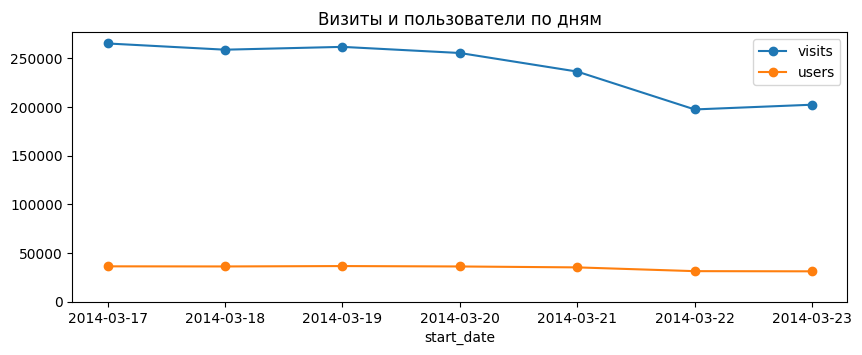

,start_date,visits,users,bounce_rate,avg_duration_s
0,2014-03-17,265108,36201,0.318,367.1
1,2014-03-18,258723,36083,0.321,366.0
2,2014-03-19,261624,36479,0.319,369.5
3,2014-03-20,255328,36065,0.320,361.7
4,2014-03-21,236232,35120,0.319,358.9
5,2014-03-22,197354,31256,0.321,352.7
6,2014-03-23,202212,31075,0.325,336.4


In [9]:
d = res["по дням"]
ax = d.plot(x="start_date", y=["visits", "users"], marker="o", title="Визиты и пользователи по дням")
ax.set_ylim(0); plt.show()
d

### 3.2 Источники трафика

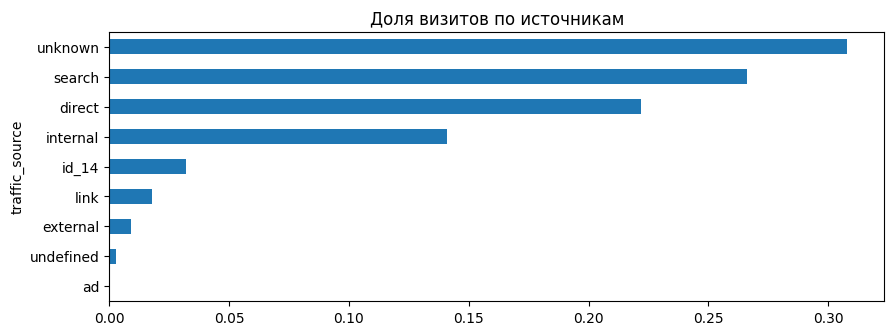

,traffic_source,visits,bounce_rate,avg_duration_s,share
0,unknown,516436,0.298,429.5,0.308
1,search,446769,0.347,242.2,0.266
2,direct,372531,0.358,260.1,0.222
3,internal,236651,0.247,615.1,0.141
4,id_14,52949,0.338,268.5,0.032
5,link,30513,0.255,301.7,0.018
6,external,15574,0.585,317.0,0.009
7,undefined,4737,0.280,498.2,0.003
8,ad,421,0.276,555.2,0.000


In [10]:
s = res["источники"].assign(share=lambda x: (x.visits / x.visits.sum()).round(3))
s.plot.barh(x="traffic_source", y="share", legend=False, title="Доля визитов по источникам").invert_yaxis()
plt.show()
s

### 3.3 Устройства

In [11]:
res["устройства"]

,device,visits,bounce_rate,avg_duration_s,avg_page_views
0,desktop,1387596,0.302,374.3,4.10
1,mobile,288985,0.406,290.8,3.64


### 3.4 Цели и конверсия

In [12]:
print("визитов хотя бы с одной целью:", visits.where(F.size("goals") > 0).count(), "из", visits.count())
res["топ целей"]

визитов хотя бы с одной целью: 167344 из 1676581


,counter_id,goal_id,reaches,visits_with_goal
0,912887,1105530,175108,8554
1,842440,3260701,25862,15591
2,10956685,2702888,25836,1007
3,28504520,3215337,25530,1000
4,842440,3209549,20615,13104
5,842440,3704014,20613,13104
6,22999378,3218203,14299,7816
7,28504520,2442563,11434,749
8,906764,1716085,11412,6371
9,15476556,3684882,10014,243


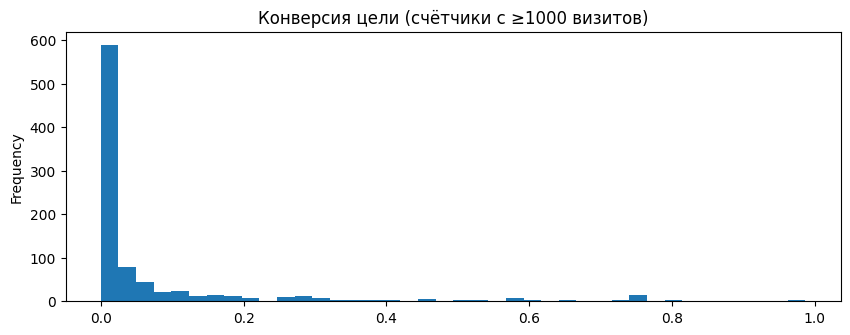

count    896.000000
mean       0.075012
std        0.164529
min        0.000100
25%        0.002000
50%        0.008500
75%        0.050525
max        0.987100
Name: conversion, dtype: float64

In [13]:
c = res["конверсия"]
c["conversion"].plot.hist(bins=40, title="Конверсия цели (счётчики с ≥1000 визитов)"); plt.show()
c["conversion"].describe()

### 3.5 Регионы и время суток

In [14]:
res["регионы"]

,region_id,visits,users
0,141,237322,9369
1,2,79724,3339
2,203,61870,4318
3,133,57894,3480
4,249,41118,1619
5,158,28922,1173
6,15078,25120,4471
7,15332,24347,4427
8,55,21323,1238
9,36,20511,829


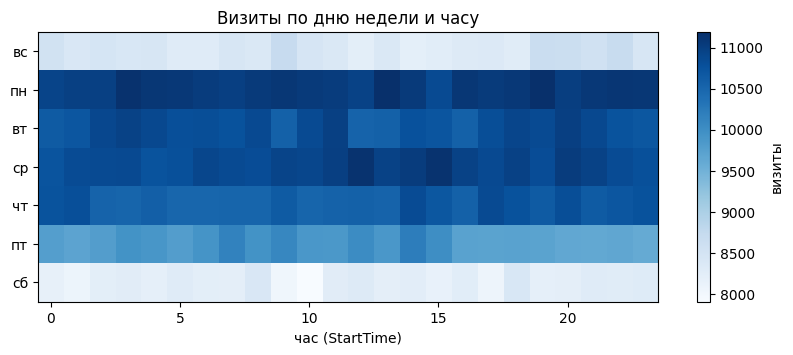

In [15]:
h = res["день недели × час"].pivot(index="dow", columns="hour", values="count")
plt.imshow(h, aspect="auto", cmap="Blues"); plt.colorbar(label="визиты")
plt.yticks(range(7), ["вс", "пн", "вт", "ср", "чт", "пт", "сб"]); plt.xlabel("час (StartTime)")
plt.title("Визиты по дню недели и часу"); plt.show()

## 4. Сжатый и несжатый вид

Те же 7 запросов в двух вариантах:

* **TSV** — исходный текстовый файл без сжатия, загруженный как есть в `s3://raw/tsv/`.
  Без transform каждый запрос сам делает всю работу: разбор текста, типы,
  схлопывание по `Sign`. Используются те же функции, что в `transform.py`.
* **warehouse** — Parquet + zstd: типы, схлопнуто, партиции по дню, сортировка по счётчику.

Время — медиана 3 прогонов. «Прочитано» — `inputBytes` стадий запроса из REST API Spark UI.
Ответы обоих вариантов сравниваются построчно.

In [16]:
TSV = "s3a://raw/tsv/visits_v1.tsv"
try:
    s3.head_object(Bucket="raw", Key="tsv/visits_v1.tsv")
except s3.exceptions.ClientError:
    s3.upload_file("/data/visits_v1.tsv", "raw", "tsv/visits_v1.tsv")

from pyspark.sql.types import StructType, StructField, StringType

def tsv_visits():
    df = (spark.read.schema(StructType([StructField(n, StringType()) for n in RAW_NAMES]))
          .option("sep", "\t").option("quote", "").csv(TSV)
          .withColumn("_part", F.lit("tsv")).withColumn("_row", F.monotonically_increasing_id()))
    return collapse(typed_visits(df))

sc = spark.sparkContext
API = f"{sc.uiWebUrl}/api/v1/applications/{sc.applicationId}"
get = lambda p: json.load(urllib.request.urlopen(API + p))

def input_mb(group):
    stages = {s for j in get("/jobs") if j.get("jobGroup") == group for s in j["stageIds"]}
    return round(sum(s["inputBytes"] for s in get("/stages") if s["stageId"] in stages) / 2**20, 1)

def bench(name, layer, make, runs=3):
    times = []
    for i in range(runs):
        g = f"{name}|{layer}|{i}"; sc.setJobGroup(g, g)
        t = time.perf_counter(); out = make().toPandas(); times.append(time.perf_counter() - t)
    time.sleep(1)
    return round(statistics.median(times), 2), input_mb(g), out

rows = []
for name, q in QUERIES.items():
    t_tsv, mb_tsv, out_tsv = bench(name, "tsv", lambda: q(tsv_visits()))
    t_wh, mb_wh, out_wh = bench(name, "warehouse", lambda: q(visits))
    same = out_tsv.reset_index(drop=True).equals(out_wh.reset_index(drop=True))
    rows.append((name, t_tsv, t_wh, round(t_tsv / t_wh), mb_tsv, mb_wh, same))
    print(rows[-1])
sc.setJobGroup("other", "other")
bench_df = pd.DataFrame(rows, columns=["запрос", "TSV, с", "warehouse, с", "ускорение ×",
                                       "TSV прочитано, МБ", "warehouse прочитано, МБ", "ответ совпал"])
bench_df

('по дням', 2.91, 0.27, 11, 2535.5, 7.7, True)


('источники', 3.87, 0.22, 18, 2535.5, 3.3, True)


('устройства', 4.23, 0.22, 19, 2535.5, 3.7, True)


('топ целей', 7.0, 0.31, 23, 2535.5, 17.1, True)


('конверсия', 9.95, 0.45, 22, 5071.0, 26.3, True)


('регионы', 5.06, 0.2, 25, 2535.5, 7.4, True)


('день недели × час', 4.41, 0.17, 26, 2535.5, 8.4, True)


,запрос,"TSV, с","warehouse, с",ускорение ×,"TSV прочитано, МБ","warehouse прочитано, МБ",ответ совпал
0,по дням,2.91,0.27,11,2535.5,7.7,True
1,источники,3.87,0.22,18,2535.5,3.3,True
2,устройства,4.23,0.22,19,2535.5,3.7,True
3,топ целей,7.00,0.31,23,2535.5,17.1,True
4,конверсия,9.95,0.45,22,5071.0,26.3,True
5,регионы,5.06,0.20,25,2535.5,7.4,True
6,день недели × час,4.41,0.17,26,2535.5,8.4,True


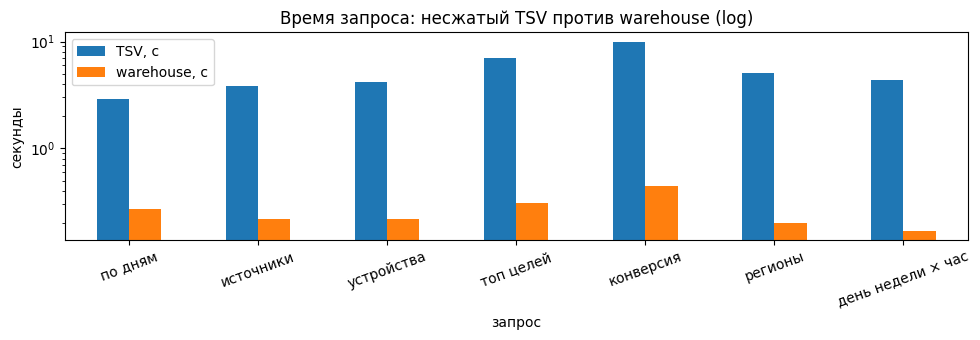

In [17]:
ax = bench_df.plot.bar(x="запрос", y=["TSV, с", "warehouse, с"], logy=True, rot=20,
                       title="Время запроса: несжатый TSV против warehouse (log)")
ax.set_ylabel("секунды"); plt.tight_layout(); plt.show()
bench_df.to_csv("/work/report/benchmark.csv", index=False)
sizes.to_csv("/work/report/layer_sizes.csv", index=False)

In [18]:
spark.stop()